In [2]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# 1. Load and prepare data
# ==========================================
DATA_DIR = r"D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT\FD002"
print(os.listdir(DATA_DIR))  # must show train_FD002.txt, test_FD002.txt, RUL_FD002.txt

index_names = ["engine_id", "cycle"]
setting_names = ["setting_1", "setting_2", "setting_3"]
sensor_names = [f"sensor_{i}" for i in range(1, 22)]
column_names = index_names + setting_names + sensor_names

df = pd.read_csv(
    os.path.join(DATA_DIR, "train_FD002.txt"),
    sep=r"\s+",
    header=None,
    names=column_names,
)

# RUL with clipping at 125
max_cycles = df.groupby("engine_id")["cycle"].max().reset_index()
max_cycles.columns = ["engine_id", "max_cycle"]
df = df.merge(max_cycles, on="engine_id", how="left")
df["RUL"] = df["max_cycle"] - df["cycle"]
df["RUL"] = df["RUL"].clip(upper=125)
df.drop(columns=["max_cycle"], inplace=True)

# Features: drop constant columns, then scale
feature_cols = [c for c in df.columns if c not in ["engine_id", "cycle", "RUL"]]
constant_cols = [c for c in feature_cols if df[c].nunique() == 1]
feature_cols = [c for c in feature_cols if c not in constant_cols]

scaler_X = MinMaxScaler()
df[feature_cols] = scaler_X.fit_transform(df[feature_cols])

# Sequences (length = 50)
SEQUENCE_LENGTH = 50
X_list, y_list = [], []
for engine_id, group in df.groupby("engine_id"):
    data_matrix = group[feature_cols].values.astype(np.float32)
    target_vector = group["RUL"].values.astype(np.float32)
    n = data_matrix.shape[0]
    if n >= SEQUENCE_LENGTH:
        for start in range(n - SEQUENCE_LENGTH + 1):
            stop = start + SEQUENCE_LENGTH
            X_list.append(data_matrix[start:stop, :])
            y_list.append(target_vector[stop - 1])

X = np.array(X_list, dtype=np.float32)
y = np.array(y_list, dtype=np.float32)

# ==========================================
# 2. Target scaling
# ==========================================
scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1))

X_train, X_test, y_train, y_test_scaled = train_test_split(
    X, y_scaled, test_size=0.2, random_state=42
)
input_shape = (X_train.shape[1], X_train.shape[2])

# ==========================================
# 3. Model
# ==========================================
bilstm_model = Sequential(
    [
        Bidirectional(
            LSTM(100, activation="tanh", return_sequences=True), input_shape=input_shape
        ),
        Dropout(0.2),
        Bidirectional(LSTM(50, activation="tanh", return_sequences=False)),
        Dropout(0.2),
        Dense(50, activation="relu"),
        Dense(1, activation="sigmoid"),
    ]
)
bilstm_model.compile(optimizer=Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=0.00001, verbose=1
    ),
]

history = bilstm_model.fit(
    X_train,
    y_train,
    epochs=40,
    batch_size=64,
    validation_split=0.15,
    callbacks=callbacks,
    verbose=1,
)

# ==========================================
# 4. Validation metrics (on a random 20% of TRAINING windows)
# ==========================================
y_pred_scaled = bilstm_model.predict(X_test, verbose=0)
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()
y_test_original = scaler_y.inverse_transform(y_test_scaled).flatten()

print("\nValidation (train split) metrics")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_original, y_pred)):.2f}")
print(f"MAE : {mean_absolute_error(y_test_original, y_pred):.2f}")
print(f"R2  : {r2_score(y_test_original, y_pred):.4f}")

['NTI_notebookdf002.ipynb', 'RUL_FD002.txt', 'test_FD002.txt', 'train_FD002.txt']

Epoch 1/40


436/436 [==============================] - 118s 214ms/step - loss: 0.0685 - mae: 0.2187 - val_loss: 0.0367 - val_mae: 0.1537 - lr: 0.0010
Epoch 2/40
436/436 [==============================] - 87s 200ms/step - loss: 0.0416 - mae: 0.1646 - val_loss: 0.0423 - val_mae: 0.1642 - lr: 0.0010
Epoch 3/40
436/436 [==============================] - 97s 223ms/step - loss: 0.0310 - mae: 0.1397 - val_loss: 0.0230 - val_mae: 0.1153 - lr: 0.0010
Epoch 4/40
436/436 [==============================] - 79s 181ms/step - loss: 0.0226 - mae: 0.1173 - val_loss: 0.0240 - val_mae: 0.1187 - lr: 0.0010
Epoch 5/40
436/436 [==============================] - 89s 205ms/step - loss: 0.0183 - mae: 0.1036 - val_loss: 0.0211 - val_mae: 0.1094 - lr: 0.0010
Epoch 6/40
436/436 [==============================] - 79s 182ms/step - loss: 0.0169 - mae: 0.0991 - val_loss: 0.0142 - val_mae: 0.0906 - lr: 0.0010
Epoch 7/40
436/436 [======

In [ ]:
# 1. Load official test data and true RUL
test_df = pd.read_csv(
    os.path.join(DATA_DIR, "test_FD002.txt"),
    sep=r"\s+",
    header=None,
    names=column_names,
)
true_rul = pd.read_csv(
    os.path.join(DATA_DIR, "RUL_FD002.txt"), sep=r"\s+", header=None, names=["RUL"]
)

# 2. Same scaling as training
test_df[feature_cols] = scaler_X.transform(test_df[feature_cols])

# 3. Last SEQUENCE_LENGTH cycles per engine (pad short engines with the first row)
engine_ids, X_last = [], []
for eid, g in test_df.groupby("engine_id"):
    data = g[feature_cols].values.astype(np.float32)
    if len(data) >= SEQUENCE_LENGTH:
        seq = data[-SEQUENCE_LENGTH:]
    else:
        pad = np.repeat(data[:1], SEQUENCE_LENGTH - len(data), axis=0)
        seq = np.vstack([pad, data])
    engine_ids.append(eid)
    X_last.append(seq)
X_last = np.array(X_last, dtype=np.float32)

# 4. Predict and return to the real RUL scale
pred_rul = scaler_y.inverse_transform(bilstm_model.predict(X_last, verbose=0)).flatten()

# 5. Save results (same format as FD001)
results_df = pd.DataFrame(
    {
        "Engine_ID": engine_ids,
        "Actual_RUL": true_rul["RUL"].values,
        "Predicted_RUL": pred_rul,
    }
)
results_df.to_csv("Predicted_RUL_Results_FD002.csv", index=False)

print(results_df.shape)  # expect (259, 3)
print(results_df.head())
print("Test MAE :", np.mean(np.abs(results_df.Actual_RUL - results_df.Predicted_RUL)))
print(
    "Test RMSE:",
    np.sqrt(np.mean((results_df.Actual_RUL - results_df.Predicted_RUL) ** 2)),
)

(259, 3)
   Engine_ID  Actual_RUL  Predicted_RUL
0          1          18      12.981105
1          2          79     123.678810
2          3         106     114.517357
3          4         110     108.696304
4          5          15      16.400084
Test MAE : 18.469632932118007
Test RMSE: 27.82787792184366


In [4]:
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text

# ---- change only these two lines per notebook ----
DATASET = "FD002"
CSV_PATH = "Predicted_RUL_Results_FD002.csv"
# --------------------------------------------------

df_sql = pd.read_csv(CSV_PATH)
assert {"Engine_ID", "Actual_RUL", "Predicted_RUL"} <= set(
    df_sql.columns
), "Unexpected columns"
assert df_sql["Engine_ID"].is_unique, "Duplicate engine IDs in the CSV"
assert (
    df_sql[["Actual_RUL", "Predicted_RUL"]].notna().all().all()
), "Missing values in the CSV"

df_out = pd.DataFrame(
    {
        "dataset": DATASET,
        "engine_id": df_sql["Engine_ID"].astype(int),
        "actual_rul": df_sql["Actual_RUL"].astype(float),
        "predicted_rul": df_sql["Predicted_RUL"].astype(float),
    }
)

odbc = (
    "DRIVER={ODBC Driver 18 for SQL Server};SERVER=localhost;DATABASE=EngineRUL;"
    "Trusted_Connection=yes;TrustServerCertificate=yes;"
)
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc))

with engine.begin() as conn:
    conn.execute(
        text("DELETE FROM dbo.rul_predictions WHERE dataset = :ds"), {"ds": DATASET}
    )
    df_out.to_sql(
        "rul_predictions", conn, schema="dbo", if_exists="append", index=False
    )

with engine.connect() as conn:
    n = conn.execute(
        text("SELECT COUNT(*) FROM dbo.rul_predictions WHERE dataset = :ds"),
        {"ds": DATASET},
    ).scalar()
print(f"{DATASET}: {len(df_out)} rows sent, {n} rows now in SQL Server")
assert n == len(df_out), "Row count mismatch!"

FD002: 259 rows sent, 259 rows now in SQL Server


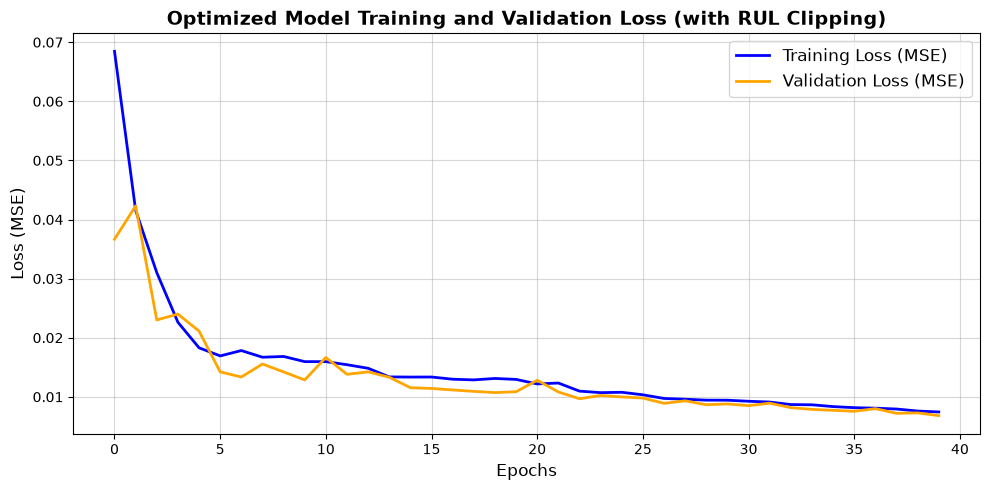

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. رسم منحنى الـ Loss (Training vs Validation Loss)
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='blue', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='orange', linewidth=2)

plt.title('Optimized Model Training and Validation Loss (with RUL Clipping)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle='-', alpha=0.5)
plt.tight_layout()

# حفظ رسمة الـ Loss كصورة
# plt.savefig('training_validation_loss.png', dpi=300)
plt.show()

# ==========================================
# 2. حفظ القيم الحقيقية والمتوقعة في ملف CSV
# ==========================================
results_df = pd.DataFrame({
    "Actual_RUL": y_test_original,
    "Predicted_RUL": y_pred,
})

# csv_filename = 'rul_predictions_comparison.csv'
# results_df.to_csv(csv_filename, index=False)
# print(f"✅ تم حفظ ملف الـ CSV بنجاح باسم: {csv_filename}")

In [6]:
import pandas as pd
import numpy as np

# 1. تجميع الـ engine_id المقابل لكل عينة اختبار بطريقة مباشرة وآمنة
# بما أننا قمنا بـ train_test_split على (X و y_scaled) بنفس الـ random_state=42، 
# سنقوم ببناء مصفوفة الـ engine_ids بالتوازي مع بناء الـ X_list منذ البداية:

engine_ids_list = []
for engine_id, group in df.groupby('engine_id'):
    data_matrix = group[feature_cols].values.astype(np.float32)
    num_elements = data_matrix.shape[0]
    if num_elements >= SEQUENCE_LENGTH:
        for start in range(num_elements - SEQUENCE_LENGTH + 1):
            engine_ids_list.append(engine_id)

engine_ids_array = np.array(engine_ids_list)

# تقسيم الـ engine_ids بنفس التقسيم בדיוק (باستخدام نفس الـ X و y لضمان التوافق)
_, _, _, _, train_engines, test_engines = train_test_split(
    X, y_scaled, engine_ids_array, test_size=0.2, random_state=42
)

# 2. ربط الـ Engine ID بالتنبؤات والقيَم الحقيقية لمجموعة الاختبار
engine_eval_df = pd.DataFrame({
    'engine_id': test_engines,
    'Actual_RUL': y_test_original,
    'Predicted_RUL': y_pred
})

# 3. التجميع على مستوى المحرك (Engine-Level Aggregation)
engine_grouped = engine_eval_df.groupby('engine_id').agg({
    'Actual_RUL': 'mean',
    'Predicted_RUL': 'mean'
}).reset_index()

# حساب الفرق المطلق ونسبة الدقة لكل محرك
engine_grouped['Absolute_Error'] = np.abs(engine_grouped['Actual_RUL'] - engine_grouped['Predicted_RUL'])
engine_grouped['Accuracy_Percentage'] = (1.0 - (engine_grouped['Absolute_Error'] / (engine_grouped['Actual_RUL'] + 1e-5))) * 100
engine_grouped['Accuracy_Percentage'] = engine_grouped['Accuracy_Percentage'].clip(lower=0)

# 4. بناء جدول فئات الدقة بناءً على عدد المحركات الفعلي
thresholds = [90, 80, 70, 60]
tier_data = []
total_test_engines = len(engine_grouped)

for thresh in thresholds:
    filtered_df = engine_grouped[engine_grouped['Accuracy_Percentage'] >= thresh]
    
    count = len(filtered_df)
    percentage = (count / total_test_engines) * 100 if total_test_engines > 0 else 0
    
    avg_diff = filtered_df['Absolute_Error'].mean() if count > 0 else 0
    max_diff = filtered_df['Absolute_Error'].max() if count > 0 else 0
    
    tier_data.append({
        'Accuracy Tier': f">= {thresh}%",
        'Engine Count': count,
        'Percentage of Test Set': f"{percentage:.2f}%",
        'Avg Cycle Difference': f"{avg_diff:.2f} cycles",
        'Max Cycle Difference': f"{max_diff:.2f} cycles"
    })

engine_summary_table = pd.DataFrame(tier_data)

print("\n" + "="*70)
print(f"📊 جدول تحليل فئات الدقة على مستوى المحركات (إجمالي محركات الاختبار: {total_test_engines}):")
print("="*70)
display(engine_summary_table)

# حفظ الجدول كملف CSV
# engine_summary_table.to_csv('engine_level_accuracy_tiers.csv', index=False)
# print("\n✅ تم حفظ جدول المحركات بنجاح في ملف: engine_level_accuracy_tiers.csv")


📊 جدول تحليل فئات الدقة على مستوى المحركات (إجمالي محركات الاختبار: 260):


,Accuracy Tier,Engine Count,Percentage of Test Set,Avg Cycle Difference,Max Cycle Difference
0,>= 90%,205,78.85%,3.41 cycles,9.55 cycles
1,>= 80%,243,93.46%,4.26 cycles,15.07 cycles
2,>= 70%,257,98.85%,4.71 cycles,16.22 cycles
3,>= 60%,260,100.00%,4.82 cycles,17.43 cycles
